# A01 三份团队计划，应该选哪一份？

你负责推荐一份团队计划。输入是工期、成本、成员最大负担；输出必须说明可行性和取舍，不能用一个未经解释的总分代替判断。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 把文字要求变成表格
每行是一份方案，每列是一个越小越好的指标。硬限制先过滤；权重只能比较满足硬限制的方案。`axis=1` 表示沿一行的各列计算。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

plans = pd.DataFrame({"plan": ["快速", "均衡", "节省"],
                      "days": [7, 9, 11], "cost": [1200, 900, 700],
                      "max_hours": [36, 27, 24]})
limits = {"days": 12, "cost": 1250, "max_hours": 40}
columns = list(limits)
def feasible_mask(frame, caps):
    return np.array([all(row[key] <= cap for key, cap in caps.items())
                     for _, row in frame.iterrows()])
candidates = plans.loc[feasible_mask(plans, limits)].copy()
assert not candidates.empty
plans.to_csv(DATA_DIR / "计划.csv", index=False, encoding="utf-8-sig")
print(candidates)


  plan  days  cost  max_hours
0   快速     7  1200         36
1   均衡     9   900         27
2   节省    11   700         24


## 2. 先检查支配关系
若方案 i 在所有指标上都不比 j 差，且至少一项更好，就说 i 支配 j。双层循环刻意保留，方便逐对手算；Pareto 集不等于唯一答案。

In [3]:
def pareto_mask(values):
    values = np.asarray(values, dtype=float)
    return np.array([not any(np.all(values[j] <= values[i]) and
                             np.any(values[j] < values[i])
                             for j in range(len(values)) if j != i)
                     for i in range(len(values))])
candidates["pareto"] = pareto_mask(candidates[columns].to_numpy())
assert pareto_mask([[1, 2], [2, 3]]).tolist() == [True, False]
print(candidates[["plan", "pareto"]])


  plan  pareto
0   快速    True
1   均衡    True
2   节省    True


## 3. 用明确权重比较，再做敏感性分析
单位不同不能直接相加。用本表最小最大值归一化，再计算权重和。这个缩放依赖候选集，新增方案时应重新检查。权重由决策者给定，不是数据自动发现的真理。

In [4]:
values = candidates[columns].to_numpy(float)
span = np.ptp(values, axis=0)
normalized = (values - values.min(axis=0)) / np.where(span == 0, 1, span)
def choose(weights):
    weights = np.asarray(weights, dtype=float)
    assert len(weights) == len(columns) and np.all(weights >= 0)
    assert np.isclose(weights.sum(), 1)
    scores = normalized @ weights
    return int(np.argmin(scores)), scores
selected, scores = choose([0.5, 0.3, 0.2])
candidates["score"] = scores
sensitivity = []
for urgency in np.linspace(0, 1, 21):
    idx, _ = choose([urgency, 0.6 * (1 - urgency), 0.4 * (1 - urgency)])
    sensitivity.append({"urgency_weight": urgency,
                        "chosen": candidates.iloc[idx]["plan"]})
sensitivity = pd.DataFrame(sensitivity)
assert feasible_mask(candidates, limits).all()


## 4. 输出可复核的建议
保存原始指标、分数和随权重变化的选择。图上没有“绝对最好”的位置；建议同时交代当前权重与何时重新评估。

In [5]:
candidates.to_csv(OUT_DIR / "方案对照.csv", index=False, encoding="utf-8-sig")
sensitivity.to_csv(OUT_DIR / "权重敏感性.csv", index=False, encoding="utf-8-sig")
ax = candidates.set_index("plan")["score"].plot.bar(color=["#467a9e"] * len(candidates))
ax.set_ylabel("归一化加权代价（越小越好）")
ax.set_title("权重：工期0.5、成本0.3、负担0.2")
plt.tight_layout(); plt.savefig(OUT_DIR / "方案比较.png"); plt.close()
chosen = candidates.iloc[selected]
save_results({"chosen": chosen["plan"], "score": float(chosen["score"]),
              "feasible_count": len(candidates),
              "pareto_count": int(candidates["pareto"].sum())},
             f"在工期/成本/负担权重为0.5/0.3/0.2时，推荐{chosen['plan']}方案，"
             f"工期{chosen['days']}天、成本{chosen['cost']}、最大负担{chosen['max_hours']}小时。"
             f"当前有{int(candidates['pareto'].sum())}个非支配方案；权重或预算变化时重新比较。")


{
  "chosen": "均衡",
  "score": 0.42,
  "feasible_count": 3,
  "pareto_count": 3
}


在工期/成本/负担权重为0.5/0.3/0.2时，推荐均衡方案，工期9天、成本900、最大负担27小时。当前有3个非支配方案；权重或预算变化时重新比较。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

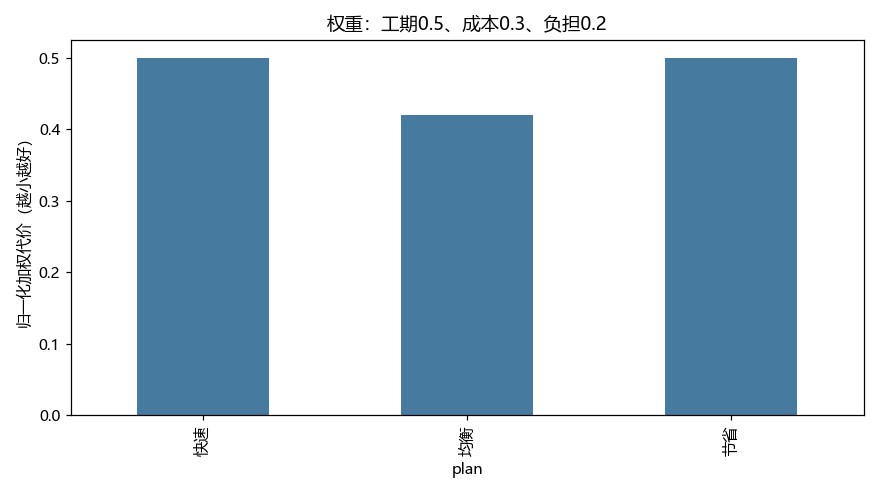

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
加权和依赖单位、归一化与权重；支配判定只对已列入的指标有效。不能把主观价值评分解释为客观事实。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。